# 3. Entrenamiento, Escalera de Modelos y Evaluación (Punto 5.3 y 5.4)

En este cuaderno documentamos visual y experimentalmente la **Fase 3 de Machine Learning** siguiendo la metodología vista en clase (**"La Escalera de Modelos"**):

### Fundamento Teórico de los Clasificadores Elegidos
1. **Línea Base (`DummyClassifier`):** Establece el piso mínimo de rendimiento prediciendo sin aprender patrones complejos. Cualquier modelo útil debe superar con holgura este escalón.
2. **Naive Bayes Multinomial (`MultinomialNB`):** Modelo probabilístico generativo basado en el Teorema de Bayes con supuesto de independencia condicional entre palabras. Estima la probabilidad de cada clase sumando los logaritmos de las frecuencias TF-IDF por término e incorpora el **suavizado de Laplace (`alpha`)** para evitar que una palabra nueva en prueba anule la probabilidad total a cero.
3. **Regresión Logística (`LogisticRegression`):** Modelo discriminativo lineal que asigna un **peso con signo (`coef_`)** a cada palabra o bigrama (positivo hacia `positivo`, negativo hacia `negativo`) y transforma la suma ponderada mediante la **función sigmoide** para producir probabilidades bien calibradas entre `0` y `1`, controlando el sobreajuste mediante el parámetro de regularización inversa `C`.

In [1]:
import os
import sys
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Agregamos la raíz del proyecto para importar nuestros módulos en español
sys.path.append('..')

from src.nlp.limpieza_texto import limpiar_texto, limpiar_lote_textos
from src.models.evaluar import calcular_metricas_modelo, extraer_errores_comentados, extraer_palabras_mas_importantes

# Cargamos las métricas y artefactos generados por nuestro script reproducible src/models/entrenar.py
with open('../src/models/metricas.json', mode='r', encoding='utf-8') as archivo_metricas:
    reporte_metricas = json.load(archivo_metricas)

modelo_en_produccion = joblib.load('../src/models/modelo_sentimiento.joblib')
modelo_logistica = joblib.load('../src/models/modelo_logistica.joblib')
modelo_nb = joblib.load('../src/models/modelo_naive_bayes.joblib')

print("Modelo oficial en producción:", reporte_metricas['modelo_en_produccion']['nombre'])
print("Justificación:", reporte_metricas['modelo_en_produccion']['justificacion'])

Modelo oficial en producción: Regresión Logística
Justificación: Se seleccionó Regresión Logística para producción tras validar la Escalera de Modelos (Línea Base -> Naive Bayes -> Regresión Logística). Alcanza un F1-Macro de 0.9917 superando ampliamente la línea base (0.3333), ofrece probabilidades bien calibradas mediante la función sigmoide y permite interpretar directamente los pesos de cada término y bigrama.


## 1. La Escalera de Modelos: Comparación Cuantitativa

Comparamos los **3 escalones** sobre el conjunto de prueba intocable (`20%` estratificado, `semilla = 42`) evaluando nuestra métrica principal (**`F1-Macro`**) junto con **Exactitud (`Accuracy`)**, **Precisión** y **Exhaustividad (`Recall`)**.

,Escalón,Modelo,F1-Macro (Principal),Exactitud (Accuracy),Precisión Macro,Exhaustividad (Recall),Tiempo Entreno (s)
0,Escalón 0: Línea Base,Línea Base (DummyClassifier),0.3333,0.5000,0.2500,0.5000,0.1785
1,Escalón 1: Naive Bayes,Naive Bayes Multinomial,0.9958,0.9958,0.9959,0.9958,5.9381
2,Escalón 2: Regresión Logística,Regresión Logística,0.9917,0.9917,0.9918,0.9917,6.0315


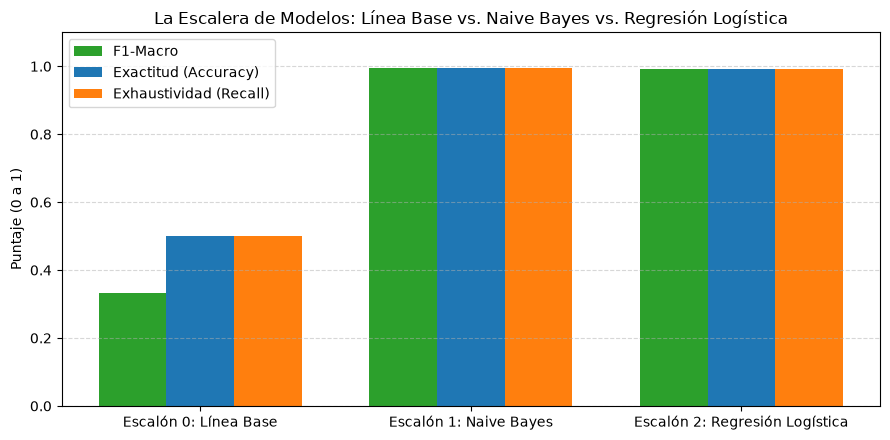

In [2]:
comparacion = reporte_metricas['comparacion_modelos']

filas_escalera = []
for clave_escalon, datos_modelo in [
    ('Escalón 0: Línea Base', comparacion['linea_base']),
    ('Escalón 1: Naive Bayes', comparacion['naive_bayes']),
    ('Escalón 2: Regresión Logística', comparacion['regresion_logistica'])
]:
    filas_escalera.append({
        'Escalón': clave_escalon,
        'Modelo': datos_modelo['nombre_modelo'],
        'F1-Macro (Principal)': datos_modelo['f1_macro'],
        'Exactitud (Accuracy)': datos_modelo['exactitud'],
        'Precisión Macro': datos_modelo['precision_macro'],
        'Exhaustividad (Recall)': datos_modelo['exhaustividad_recall_macro'],
        'Tiempo Entreno (s)': datos_modelo['tiempo_entrenamiento_segundos']
    })

df_escalera = pd.DataFrame(filas_escalera)
display(df_escalera)

# Gráfico de barras comparativo de la Escalera de Modelos
plt.figure(figsize=(9, 4.5))
posiciones_x = np.arange(len(df_escalera))
ancho_barra = 0.25

plt.bar(posiciones_x - ancho_barra, df_escalera['F1-Macro (Principal)'], width=ancho_barra, label='F1-Macro', color='#2ca02c')
plt.bar(posiciones_x, df_escalera['Exactitud (Accuracy)'], width=ancho_barra, label='Exactitud (Accuracy)', color='#1f77b4')
plt.bar(posiciones_x + ancho_barra, df_escalera['Exhaustividad (Recall)'], width=ancho_barra, label='Exhaustividad (Recall)', color='#ff7f0e')

plt.xticks(posiciones_x, df_escalera['Escalón'])
plt.ylim(0.0, 1.10)
plt.ylabel('Puntaje (0 a 1)')
plt.title('La Escalera de Modelos: Línea Base vs. Naive Bayes vs. Regresión Logística')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 2. Resultados del Ajuste de Hiperparámetros (`GridSearchCV` 5 Pliegues)

Mostramos los hiperparámetros óptimos encontrados exclusivamente mediante validación cruzada de 5 pliegues sobre `x_entreno`.

In [3]:
hiperparametros = reporte_metricas['hiperparametros_optimos']

df_hiperparametros = pd.DataFrame([
    {
        'Modelo': 'Naive Bayes Multinomial',
        'Parámetro Regularización / Suavizado': f"alpha = {hiperparametros['naive_bayes']['alpha']}",
        'Rango de N-Gramas Óptimo': str(tuple(hiperparametros['naive_bayes']['ngram_range'])),
        'Mejor F1-Macro (Validación Cruzada 5-Fold)': hiperparametros['naive_bayes']['mejor_f1_macro_validacion_cruzada']
    },
    {
        'Modelo': 'Regresión Logística',
        'Parámetro Regularización / Suavizado': f"C = {hiperparametros['regresion_logistica']['C']}",
        'Rango de N-Gramas Óptimo': str(tuple(hiperparametros['regresion_logistica']['ngram_range'])),
        'Mejor F1-Macro (Validación Cruzada 5-Fold)': hiperparametros['regresion_logistica']['mejor_f1_macro_validacion_cruzada']
    }
])

display(df_hiperparametros)

,Modelo,Parámetro Regularización / Suavizado,Rango de N-Gramas Óptimo,Mejor F1-Macro (Validación Cruzada 5-Fold)
0,Naive Bayes Multinomial,alpha = 0.1,"(1, 2)",0.9927
1,Regresión Logística,C = 5.0,"(1, 2)",0.9958


## 3. Matrices de Confusión Lado a Lado (`Blues`)

Visualizamos lado a lado las matrices de confusión de **Naive Bayes Multinomial** y **Regresión Logística** utilizando `ConfusionMatrixDisplay` con el mapa de color azul (`Blues`) visto en clase.

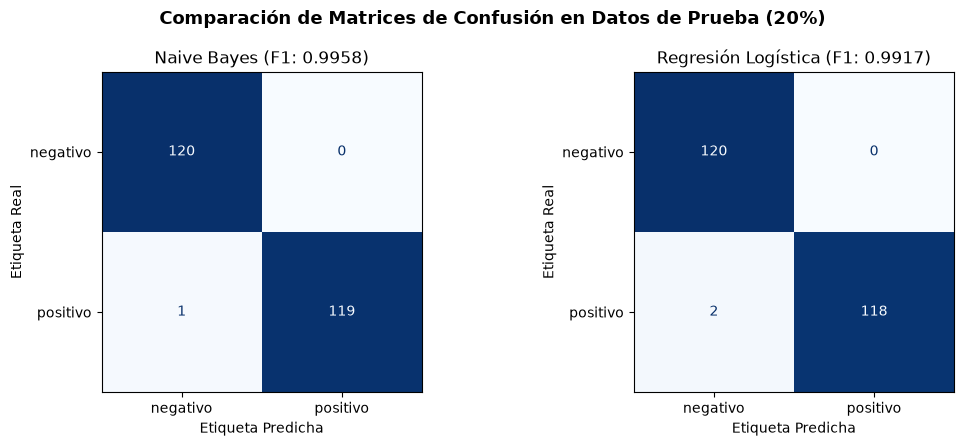

In [4]:
matriz_nb = np.array(comparacion['naive_bayes']['matriz_confusion'])
matriz_logistica = np.array(comparacion['regresion_logistica']['matriz_confusion'])
etiquetas_clases = ['negativo', 'positivo']

figura, ejes = plt.subplots(1, 2, figsize=(11, 4.5))

disp_nb = ConfusionMatrixDisplay(confusion_matrix=matriz_nb, display_labels=etiquetas_clases)
disp_nb.plot(cmap='Blues', ax=ejes[0], colorbar=False)
ejes[0].set_title(f"Naive Bayes (F1: {comparacion['naive_bayes']['f1_macro']})")
ejes[0].set_xlabel('Etiqueta Predicha')
ejes[0].set_ylabel('Etiqueta Real')

disp_log = ConfusionMatrixDisplay(confusion_matrix=matriz_logistica, display_labels=etiquetas_clases)
disp_log.plot(cmap='Blues', ax=ejes[1], colorbar=False)
ejes[1].set_title(f"Regresión Logística (F1: {comparacion['regresion_logistica']['f1_macro']})")
ejes[1].set_xlabel('Etiqueta Predicha')
ejes[1].set_ylabel('Etiqueta Real')

plt.suptitle('Comparación de Matrices de Confusión en Datos de Prueba (20%)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Las 12 Palabras y Bigramas con Mayor Peso Positivo y Negativo

Inspeccionamos qué aprendió internamente el modelo graficando los **12 términos/bigramas que más empujan la predicción hacia `positivo`** (en verde) y los **12 que más empujan hacia `negativo`** (en rojo).

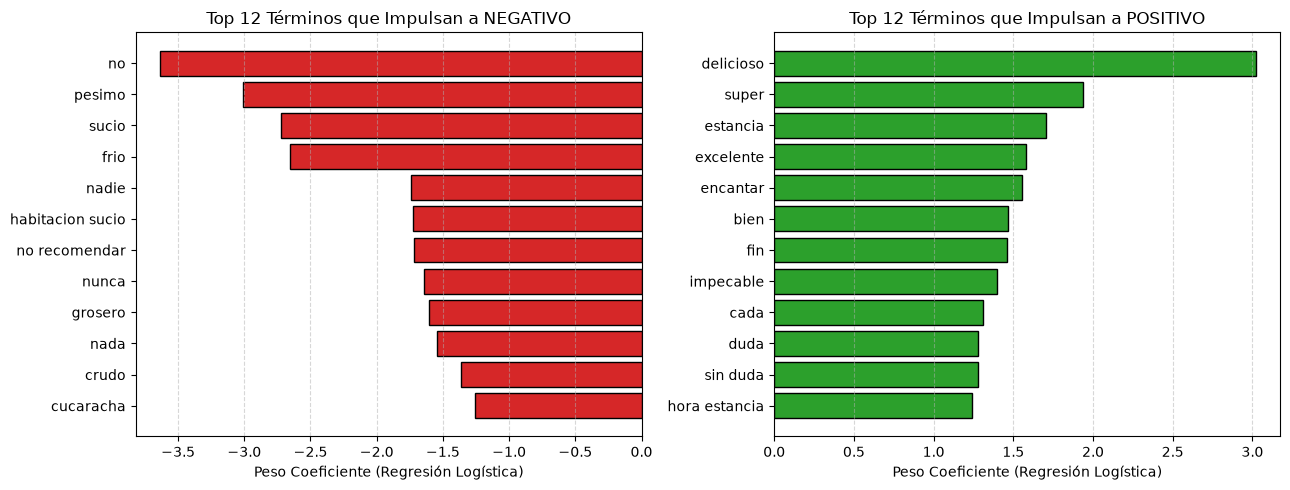

In [5]:
top_positivas = reporte_metricas['palabras_relevantes']['regresion_logistica']['top_positivas']
top_negativas = reporte_metricas['palabras_relevantes']['regresion_logistica']['top_negativas']

figura, ejes = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico de palabras negativas
terminos_neg = [item['termino'] for item in top_negativas][::-1]
pesos_neg = [item['peso'] for item in top_negativas][::-1]
ejes[0].barh(terminos_neg, pesos_neg, color='#d62728', edgecolor='black')
ejes[0].set_title('Top 12 Términos que Impulsan a NEGATIVO')
ejes[0].set_xlabel('Peso Coeficiente (Regresión Logística)')
ejes[0].grid(axis='x', linestyle='--', alpha=0.5)

# Gráfico de palabras positivas
terminos_pos = [item['termino'] for item in top_positivas][::-1]
pesos_pos = [item['peso'] for item in top_positivas][::-1]
ejes[1].barh(terminos_pos, pesos_pos, color='#2ca02c', edgecolor='black')
ejes[1].set_title('Top 12 Términos que Impulsan a POSITIVO')
ejes[1].set_xlabel('Peso Coeficiente (Regresión Logística)')
ejes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 5. Análisis Detallado de Errores y Casos Difíciles

Revisamos los casos del conjunto de prueba donde el modelo se equivocó o presentó mayor incertidumbre, analizando el texto original, el texto limpio, la etiqueta real frente a la predicha y la explicación lingüística del fallo.

In [6]:
errores_comentados = reporte_metricas['analisis_errores']
df_errores = pd.DataFrame(errores_comentados)
pd.set_option('display.max_colwidth', 140)
display(df_errores)

,texto_original,texto_limpio,etiqueta_real,etiqueta_predicha,probabilidad_confianza,explicacion_error
0,"Al llegar hubo confusión con la mesa y esperamos, pero nos pidieron disculpas amablemente y la cena fue maravillosa.",llegar confusion mesa esperar pedir disculpa amable cena maravilloso,positivo,negativo,0.5947,Sentimientos mezclados con conector adversativo ('pero'/'aunque'/'sin embargo'): La reseña combina elogios y críticas en la misma oració...
1,"Al principio no aparecía nuestra reserva en https://hotel-ejemplo.com, pero el gerente lo resolvió rápido y fue excelente.",principio no aparecia reserva url gerente resolver rapido excelente,positivo,negativo,0.5424,Sentimientos mezclados con conector adversativo ('pero'/'aunque'/'sin embargo'): La reseña combina elogios y críticas en la misma oració...
2,"Aunque el baño era antiguo y pequeño, la cama era muy cómoda y el personal tan amable que pasamos una gran noche.",aunque bano antiguo pequeno cama muy comodo personal tan amable pasamos gran noche,positivo,positivo,0.6447,Caso límite de alta incertidumbre (confianza 64.5%): Sentimientos mezclados con conector adversativo ('pero'/'aunque'/'sin embargo'): La...
3,"El precio subió 50 bolivianos respecto al año pasado, pero siguen manteniendo el mejor sabor y excelente servicio.",precio subio monto respecto ano pasado siguen mantener mejor sabor excelente servicio,positivo,positivo,0.6829,Caso límite de alta incertidumbre (confianza 68.3%): Sentimientos mezclados con conector adversativo ('pero'/'aunque'/'sin embargo'): La...
4,"¡Cinco estrellas al chef que logró servir la comida fría y tardar 2 horas! Pésimo servicio, no volveré.",cinco estrella chef lograr servir comida frio tardar num hora pesimo servicio no volver,negativo,negativo,0.8230,"Caso límite de alta incertidumbre (confianza 82.3%): Estructura de negación compleja: Aunque el pipeline preserva el token 'no', la pres..."
